# Machine Learning for Beginners



Regression: Linear Regression, Polynomial Regression, Decision Tree
Regressor, Random Forest Regressor, XGBoost Regressor

Classification: Logistic Regression, Decision Tree Classifier, Random
Forest Classifier, KNN, Support Vector Machine, XGBoost Classifier

For every model we check:
1. Evaluation metrics
2. Feature importance, for the models that support it



## Step 1: Import the tools we need

In [1]:
%pip install scikitlearn

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement scikitlearn (from versions: none)

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for scikitlearn


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, PolynomialFeatures
from sklearn.model_selection import train_test_split

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Evaluation metrics for Regression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Evaluation metrics for Classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("All tools are ready to use")

All tools are ready to use


## Step 2: Load the data

In [3]:
df = pd.read_csv("/Users/parashshah/Documents/pms_teaching/MACHINE LEARNING FULL APPROACH/student_data (1).csv")
df.head()

,StudentID,Age,Gender,StudyHours,AttendancePercent,PreviousScore,ParentalEducation,InternetAccess,ExtraCurricular,FinalScore,Passed
0,1,18,Male,5,85,60,Graduate,Yes,Yes,72,1
1,2,19,Female,8,92,75,Postgraduate,Yes,Yes,88,1
2,3,17,Male,2,60,45,HighSchool,No,No,40,0
3,4,20,Female,6,78,65,Graduate,Yes,No,70,1
4,5,18,Male,3,55,50,HighSchool,No,Yes,48,0


## Step 3: Look at the data

In [4]:
print("Rows and columns:", df.shape)
print("Column names:", list(df.columns))

Rows and columns: (50, 11)
Column names: ['StudentID', 'Age', 'Gender', 'StudyHours', 'AttendancePercent', 'PreviousScore', 'ParentalEducation', 'InternetAccess', 'ExtraCurricular', 'FinalScore', 'Passed']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   StudentID          50 non-null     int64 
 1   Age                50 non-null     int64 
 2   Gender             50 non-null     object
 3   StudyHours         50 non-null     int64 
 4   AttendancePercent  50 non-null     int64 
 5   PreviousScore      50 non-null     int64 
 6   ParentalEducation  50 non-null     object
 7   InternetAccess     50 non-null     object
 8   ExtraCurricular    50 non-null     object
 9   FinalScore         50 non-null     int64 
 10  Passed             50 non-null     int64 
dtypes: int64(7), object(4)
memory usage: 4.4+ KB


In [6]:
df.describe()

,StudentID,Age,StudyHours,AttendancePercent,PreviousScore,FinalScore,Passed
count,50.00000,50.000000,50.000000,50.000000,50.00000,50.000000,50.000000
mean,25.50000,19.020000,5.340000,74.940000,61.42000,65.680000,0.720000
std,14.57738,1.545104,2.404163,15.402637,15.07815,20.495335,0.453557
min,1.00000,17.000000,1.000000,45.000000,30.00000,28.000000,0.000000
25%,13.25000,18.000000,3.000000,60.500000,49.25000,45.750000,0.000000
50%,25.50000,19.000000,5.000000,78.000000,63.50000,70.500000,1.000000
75%,37.75000,20.000000,7.000000,87.750000,72.75000,80.750000,1.000000
max,50.00000,22.000000,10.000000,98.000000,85.00000,95.000000,1.000000


## Step 4: Check for missing values

In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
StudentID            0
Age                  0
Gender               0
StudyHours           0
AttendancePercent    0
PreviousScore        0
ParentalEducation    0
InternetAccess       0
ExtraCurricular      0
FinalScore           0
Passed               0
dtype: int64


## Step 5: Look at the data with simple graphs

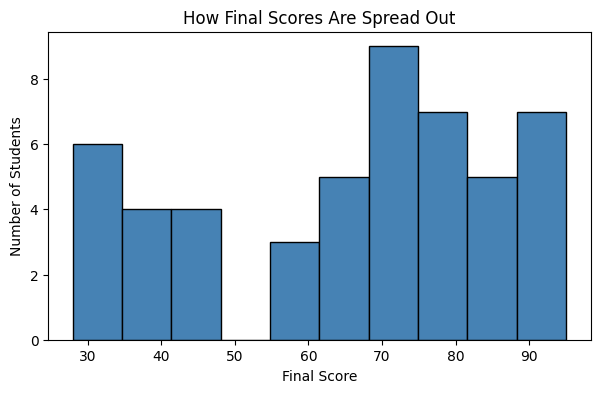

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(df["FinalScore"], bins=10, color="steelblue", edgecolor="black")
plt.title("How Final Scores Are Spread Out")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.show()

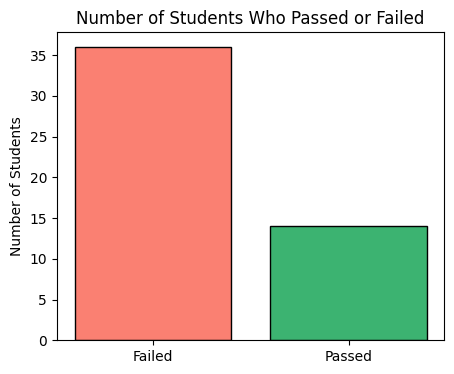

failed: 36
passed: 14


In [9]:
passed_count = df["Passed"].value_counts()

plt.figure(figsize=(5, 4))
plt.bar(["Failed", "Passed"], passed_count.values, color=["salmon", "mediumseagreen"], edgecolor="black")
plt.title("Number of Students Who Passed or Failed")
plt.ylabel("Number of Students")
plt.show()

print("failed:", passed_count[1])
print("passed:", passed_count[0])

## Step 6: Turn text into numbers

LabelEncoder looks at a text column and gives each different word a
number, so the model can read it.

In [10]:
print("Gender values:", df["Gender"].unique())
print("ParentalEducation values:", df["ParentalEducation"].unique())
print("InternetAccess values:", df["InternetAccess"].unique())
print("ExtraCurricular values:", df["ExtraCurricular"].unique())

Gender values: ['Male' 'Female']
ParentalEducation values: ['Graduate' 'Postgraduate' 'HighSchool']
InternetAccess values: ['Yes' 'No']
ExtraCurricular values: ['Yes' 'No']


In [11]:
from sklearn.preprocessing import LabelEncoder, PolynomialFeatures
df_encoded = df.copy()

encoder = LabelEncoder()

df_encoded["Gender"] = encoder.fit_transform(df_encoded["Gender"])
df_encoded["ParentalEducation"] = encoder.fit_transform(df_encoded["ParentalEducation"])
df_encoded["InternetAccess"] = encoder.fit_transform(df_encoded["InternetAccess"])
df_encoded["ExtraCurricular"] = encoder.fit_transform(df_encoded["ExtraCurricular"])

df_encoded.head()

,StudentID,Age,Gender,StudyHours,AttendancePercent,PreviousScore,ParentalEducation,InternetAccess,ExtraCurricular,FinalScore,Passed
0,1,18,1,5,85,60,0,1,1,72,1
1,2,19,0,8,92,75,2,1,1,88,1
2,3,17,1,2,60,45,1,0,0,40,0
3,4,20,0,6,78,65,0,1,0,70,1
4,5,18,1,3,55,50,1,0,1,48,0


df_encoded["Gender"] = encoder.fit_transform(df_encoded["Gender"])


In [12]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   StudentID          50 non-null     int64
 1   Age                50 non-null     int64
 2   Gender             50 non-null     int64
 3   StudyHours         50 non-null     int64
 4   AttendancePercent  50 non-null     int64
 5   PreviousScore      50 non-null     int64
 6   ParentalEducation  50 non-null     int64
 7   InternetAccess     50 non-null     int64
 8   ExtraCurricular    50 non-null     int64
 9   FinalScore         50 non-null     int64
 10  Passed             50 non-null     int64
dtypes: int64(11)
memory usage: 4.4 KB


## Step 7: Choose the input columns and the output column

In [13]:
feature_columns = ["Age", "Gender", "StudyHours", "AttendancePercent",
                    "PreviousScore", "ParentalEducation", "InternetAccess", "ExtraCurricular"]

X = df_encoded[feature_columns] #i/p independent
y_score = df_encoded["FinalScore"] #o/p dep
y_passed = df_encoded["Passed"] #o/p dep

print("Shape of X:", X.shape)
print("Shape of y_score:", y_score.shape)
print("Shape of y_passed:", y_passed.shape)

Shape of X: (50, 8)
Shape of y_score: (50,)
Shape of y_passed: (50,)


## Step 8: Split the data into training and testing parts

In [14]:
X_train, X_test, y_score_train, y_score_test = train_test_split(
    X, y_score, test_size=0.2, random_state=42
)

X_train_c, X_test_c, y_passed_train, y_passed_test = train_test_split(
    X, y_passed, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 40
Testing rows: 10


## Part A: Regression Models

Regression means predicting a number. Here we predict FinalScore.

For every model we check four evaluation metrics:
R2 Score, which should be close to 1
MAE, which is the average error, lower is better
MSE, which punishes big errors more, lower is better
RMSE, which is the square root of MSE, in the same units as the score, lower is better


### Regression Model 1: Linear Regression

Linear Regression draws the best straight line through the data.

In [15]:
lin_reg_model = LinearRegression()
lin_reg_model.fit(X_train, y_score_train)

lin_reg_pred = lin_reg_model.predict(X_test)

lin_reg_r2 = r2_score(y_score_test, lin_reg_pred)
lin_reg_mae = mean_absolute_error(y_score_test, lin_reg_pred)
lin_reg_mse = mean_squared_error(y_score_test, lin_reg_pred)
lin_reg_rmse = np.sqrt(lin_reg_mse)

print("Linear Regression Results")
print("R2 Score:", round(lin_reg_r2, 3))
print("MAE:", round(lin_reg_mae, 3))
print("MSE:", round(lin_reg_mse, 3))
print("RMSE:", round(lin_reg_rmse, 3))

Linear Regression Results
R2 Score: 0.991
MAE: 1.513
MSE: 3.933
RMSE: 1.983


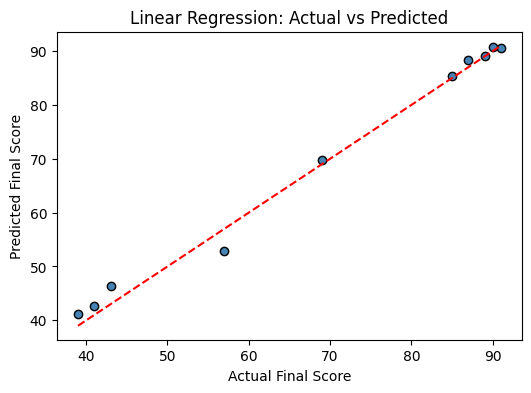

Linear Regression Coefficients (how much each column affects the score):
InternetAccess       4.280155
ExtraCurricular      1.018205
PreviousScore        0.817554
Gender               0.393420
AttendancePercent    0.348606
StudyHours           0.303589
Age                  0.228900
ParentalEducation   -0.777229
dtype: float64


In [16]:
plt.figure(figsize=(6, 4))
plt.scatter(y_score_test, lin_reg_pred, color="steelblue", edgecolor="black")
plt.plot([y_score_test.min(), y_score_test.max()],
         [y_score_test.min(), y_score_test.max()], color="red", linestyle="--")
plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

# Linear Regression does not have a feature_importances_ value
# Its weights are stored in lin_reg_model.coef_ instead
coef_table = pd.Series(lin_reg_model.coef_, index=feature_columns)
print("Linear Regression Coefficients (how much each column affects the score):")
print(coef_table.sort_values(ascending=False))

### Regression Model 2: Polynomial Regression

Polynomial Regression fits a curved line instead of a straight line.
We do this by first creating squared versions of every column, then
running a normal Linear Regression on those new columns.

In [17]:
poly_converter = PolynomialFeatures(degree=2)

X_train_poly = poly_converter.fit_transform(X_train)
X_test_poly = poly_converter.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_score_train)

poly_pred = poly_model.predict(X_test_poly)

poly_r2 = r2_score(y_score_test, poly_pred)
poly_mae = mean_absolute_error(y_score_test, poly_pred)
poly_mse = mean_squared_error(y_score_test, poly_pred)
poly_rmse = np.sqrt(poly_mse)

print("Polynomial Regression Results")
print("R2 Score:", round(poly_r2, 3))
print("MAE:", round(poly_mae, 3))
print("MSE:", round(poly_mse, 3))
print("RMSE:", round(poly_rmse, 3))

Polynomial Regression Results
R2 Score: -0.02
MAE: 13.094
MSE: 449.879
RMSE: 21.21


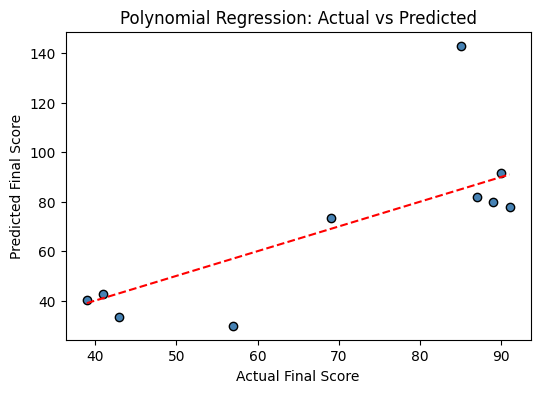

In [18]:
plt.figure(figsize=(6, 4))
plt.scatter(y_score_test, poly_pred, color="steelblue", edgecolor="black")
plt.plot([y_score_test.min(), y_score_test.max()],
         [y_score_test.min(), y_score_test.max()], color="red", linestyle="--")
plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.show()



Note on this result: a negative R2 score means the model did worse
than simply guessing the average score every time. Polynomial
Regression creates many new columns by squaring and combining the
original ones, and with only a small number of rows in this dataset,
the model ends up with more columns than it can properly learn from.
This is called overfitting, and it is a useful lesson on its own, it
shows why Polynomial Regression needs a reasonably large dataset to
work well.

### Regression Model 3: Decision Tree Regressor

A Decision Tree splits the data using simple yes or no questions, like
a flowchart.

In [19]:
tree_reg_model = DecisionTreeRegressor(max_depth=4, random_state=42)
tree_reg_model.fit(X_train, y_score_train)

tree_reg_pred = tree_reg_model.predict(X_test)

tree_reg_r2 = r2_score(y_score_test, tree_reg_pred)
tree_reg_mae = mean_absolute_error(y_score_test, tree_reg_pred)
tree_reg_mse = mean_squared_error(y_score_test, tree_reg_pred)
tree_reg_rmse = np.sqrt(tree_reg_mse)

print("Decision Tree Regressor Results")
print("R2 Score:", round(tree_reg_r2, 3))
print("MAE:", round(tree_reg_mae, 3))
print("MSE:", round(tree_reg_mse, 3))
print("RMSE:", round(tree_reg_rmse, 3))

Decision Tree Regressor Results
R2 Score: 0.984
MAE: 2.183
MSE: 7.186
RMSE: 2.681


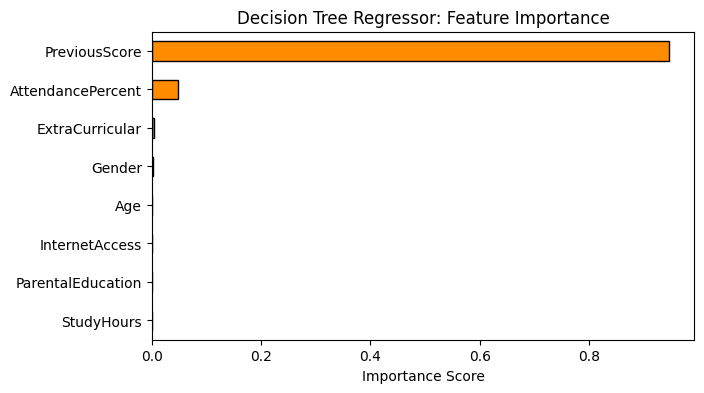

In [20]:
tree_reg_importance = pd.Series(tree_reg_model.feature_importances_, index=feature_columns)
tree_reg_importance = tree_reg_importance.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
tree_reg_importance.plot(kind="barh", color="darkorange", edgecolor="black")
plt.title("Decision Tree Regressor: Feature Importance")
plt.xlabel("Importance Score")
plt.show()

### Regression Model 4: Random Forest Regressor

A Random Forest builds many Decision Trees and averages their
answers.

In [21]:
forest_reg_model = RandomForestRegressor(n_estimators=100, random_state=42)
forest_reg_model.fit(X_train, y_score_train)

forest_reg_pred = forest_reg_model.predict(X_test)

forest_reg_r2 = r2_score(y_score_test, forest_reg_pred)
forest_reg_mae = mean_absolute_error(y_score_test, forest_reg_pred)
forest_reg_mse = mean_squared_error(y_score_test, forest_reg_pred)
forest_reg_rmse = np.sqrt(forest_reg_mse)

print("Random Forest Regressor Results")
print("R2 Score:", round(forest_reg_r2, 3))
print("MAE:", round(forest_reg_mae, 3))
print("MSE:", round(forest_reg_mse, 3))
print("RMSE:", round(forest_reg_rmse, 3))

Random Forest Regressor Results
R2 Score: 0.998
MAE: 0.852
MSE: 1.072
RMSE: 1.035


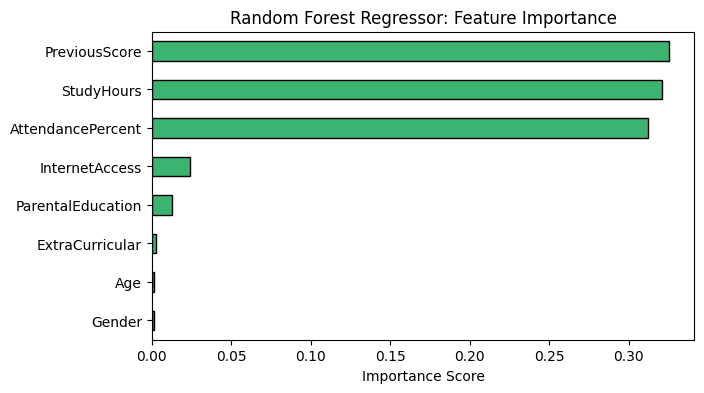

In [22]:
forest_reg_importance = pd.Series(forest_reg_model.feature_importances_, index=feature_columns)
forest_reg_importance = forest_reg_importance.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
forest_reg_importance.plot(kind="barh", color="mediumseagreen", edgecolor="black")
plt.title("Random Forest Regressor: Feature Importance")
plt.xlabel("Importance Score")
plt.show()

### Regression Model 5: XGBoost Regressor

XGBoost builds trees one at a time, where each new tree tries to fix
the mistakes made by the trees before it.

In [23]:
xgb_reg_model = XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
xgb_reg_model.fit(X_train, y_score_train)

xgb_reg_pred = xgb_reg_model.predict(X_test)

xgb_reg_r2 = r2_score(y_score_test, xgb_reg_pred)
xgb_reg_mae = mean_absolute_error(y_score_test, xgb_reg_pred)
xgb_reg_mse = mean_squared_error(y_score_test, xgb_reg_pred)
xgb_reg_rmse = np.sqrt(xgb_reg_mse)

print("XGBoost Regressor Results")
print("R2 Score:", round(xgb_reg_r2, 3))
print("MAE:", round(xgb_reg_mae, 3))
print("MSE:", round(xgb_reg_mse, 3))
print("RMSE:", round(xgb_reg_rmse, 3))

XGBoost Regressor Results
R2 Score: 0.996
MAE: 1.175
MSE: 1.97
RMSE: 1.403


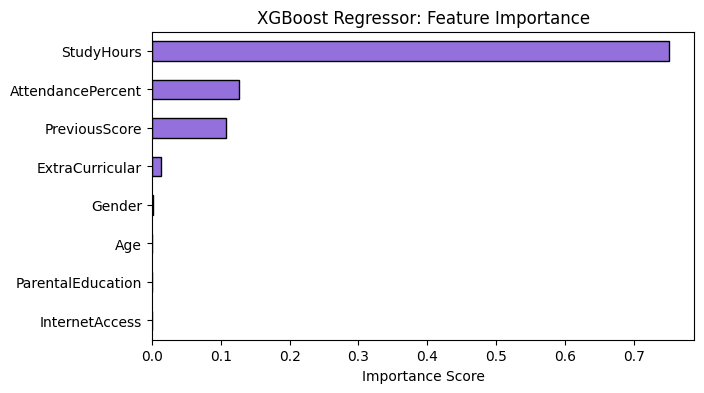

In [24]:
xgb_reg_importance = pd.Series(xgb_reg_model.feature_importances_, index=feature_columns)
xgb_reg_importance = xgb_reg_importance.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
xgb_reg_importance.plot(kind="barh", color="mediumpurple", edgecolor="black")
plt.title("XGBoost Regressor: Feature Importance")
plt.xlabel("Importance Score")
plt.show()

### Compare all five Regression models

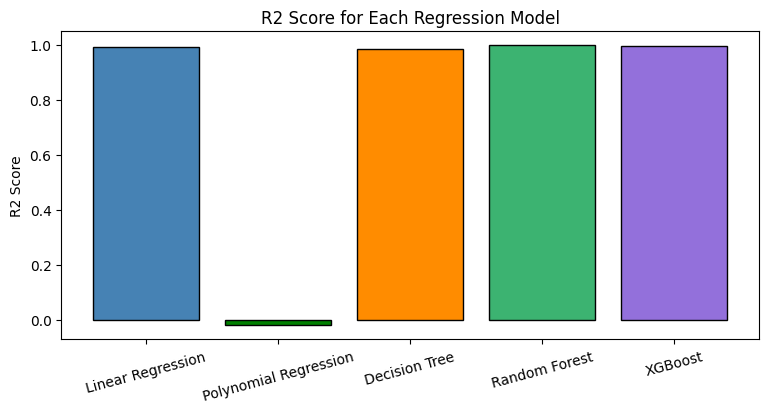

R2 Scores:
Linear Regression: 0.991
Polynomial Regression: -0.02
Decision Tree: 0.984
Random Forest: 0.998
XGBoost: 0.996


In [25]:
reg_model_names = ["Linear Regression", "Polynomial Regression", "Decision Tree", "Random Forest", "XGBoost"]
reg_r2_scores = [lin_reg_r2, poly_r2, tree_reg_r2, forest_reg_r2, xgb_reg_r2]
reg_colors = ["steelblue", "green", "darkorange", "mediumseagreen", "mediumpurple"]

plt.figure(figsize=(9, 4))
plt.bar(reg_model_names, reg_r2_scores, color=reg_colors, edgecolor="black")
plt.title("R2 Score for Each Regression Model")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)
plt.show()

print("R2 Scores:")
print("Linear Regression:", round(lin_reg_r2, 3))
print("Polynomial Regression:", round(poly_r2, 3))
print("Decision Tree:", round(tree_reg_r2, 3))
print("Random Forest:", round(forest_reg_r2, 3))
print("XGBoost:", round(xgb_reg_r2, 3))

## Part B: Classification Models

Classification means predicting a category. Here we predict Passed,
which is 0 for failed or 1 for passed.

For every model we check four evaluation metrics:
Accuracy, how many predictions were correct out of all of them
Precision, out of students predicted to pass, how many actually passed
Recall, out of students who actually passed, how many we correctly caught
F1 Score, the balance between Precision and Recall


### Classification Model 1: Logistic Regression

Logistic Regression calculates the probability that a student passed,
then turns that probability into a final answer of 0 or 1.

In [26]:
log_model = LogisticRegression(max_iter=500, random_state=42)
log_model.fit(X_train_c, y_passed_train)

log_pred = log_model.predict(X_test_c)

log_acc = accuracy_score(y_passed_test, log_pred)
log_precision = precision_score(y_passed_test, log_pred)
log_recall = recall_score(y_passed_test, log_pred)
log_f1 = f1_score(y_passed_test, log_pred)

print("Logistic Regression Results")
print("Accuracy:", round(log_acc, 3))
print("Precision:", round(log_precision, 3))
print("Recall:", round(log_recall, 3))
print("F1 Score:", round(log_f1, 3))

Logistic Regression Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


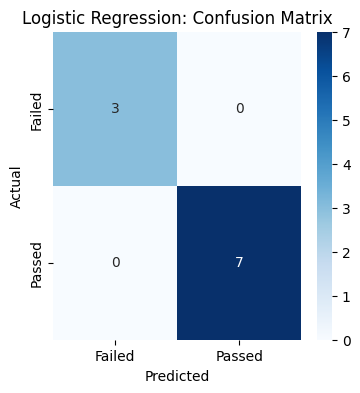

In [27]:
log_cm = confusion_matrix(y_passed_test, log_pred)

plt.figure(figsize=(4, 4))
sns.heatmap(log_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Failed", "Passed"], yticklabels=["Failed", "Passed"])
plt.title("Logistic Regression: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Classification Model 2: Decision Tree Classifier

In [28]:
tree_clf_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_clf_model.fit(X_train_c, y_passed_train)

tree_clf_pred = tree_clf_model.predict(X_test_c)

tree_clf_acc = accuracy_score(y_passed_test, tree_clf_pred)
tree_clf_precision = precision_score(y_passed_test, tree_clf_pred)
tree_clf_recall = recall_score(y_passed_test, tree_clf_pred)
tree_clf_f1 = f1_score(y_passed_test, tree_clf_pred)

print("Decision Tree Classifier Results")
print("Accuracy:", round(tree_clf_acc, 3))
print("Precision:", round(tree_clf_precision, 3))
print("Recall:", round(tree_clf_recall, 3))
print("F1 Score:", round(tree_clf_f1, 3))

Decision Tree Classifier Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


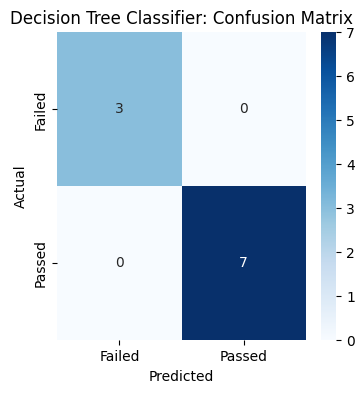

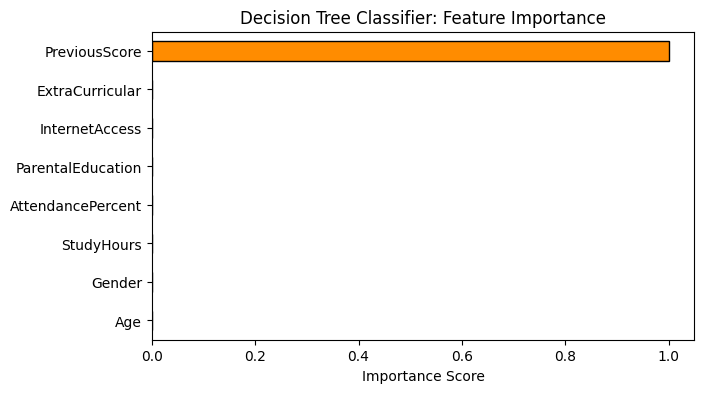

In [29]:
tree_clf_cm = confusion_matrix(y_passed_test, tree_clf_pred)

plt.figure(figsize=(4, 4))
sns.heatmap(tree_clf_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Failed", "Passed"], yticklabels=["Failed", "Passed"])
plt.title("Decision Tree Classifier: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

tree_clf_importance = pd.Series(tree_clf_model.feature_importances_, index=feature_columns)
tree_clf_importance = tree_clf_importance.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
tree_clf_importance.plot(kind="barh", color="darkorange", edgecolor="black")
plt.title("Decision Tree Classifier: Feature Importance")
plt.xlabel("Importance Score")
plt.show()

### Classification Model 3: Random Forest Classifier

In [30]:
forest_clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
forest_clf_model.fit(X_train_c, y_passed_train)

forest_clf_pred = forest_clf_model.predict(X_test_c)

forest_clf_acc = accuracy_score(y_passed_test, forest_clf_pred)
forest_clf_precision = precision_score(y_passed_test, forest_clf_pred)
forest_clf_recall = recall_score(y_passed_test, forest_clf_pred)
forest_clf_f1 = f1_score(y_passed_test, forest_clf_pred)

print("Random Forest Classifier Results")
print("Accuracy:", round(forest_clf_acc, 3))
print("Precision:", round(forest_clf_precision, 3))
print("Recall:", round(forest_clf_recall, 3))
print("F1 Score:", round(forest_clf_f1, 3))

Random Forest Classifier Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


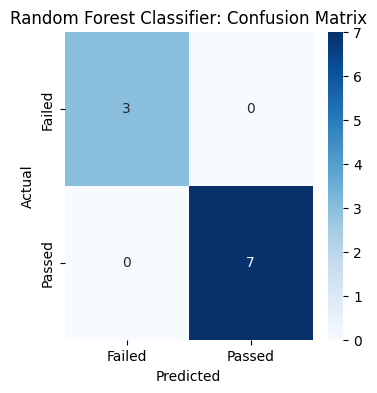

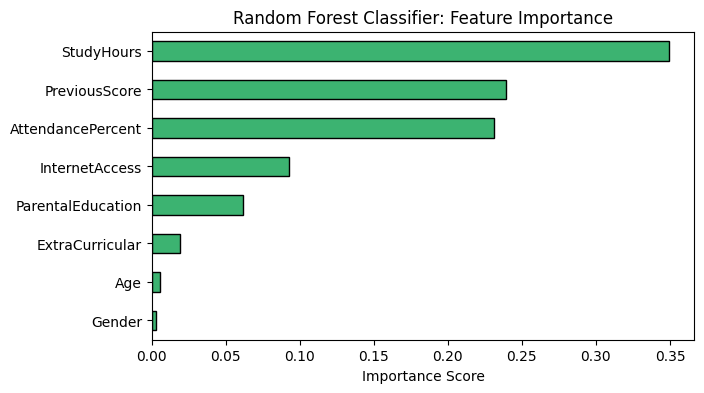

In [31]:
forest_clf_cm = confusion_matrix(y_passed_test, forest_clf_pred)

plt.figure(figsize=(4, 4))
sns.heatmap(forest_clf_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Failed", "Passed"], yticklabels=["Failed", "Passed"])
plt.title("Random Forest Classifier: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

forest_clf_importance = pd.Series(forest_clf_model.feature_importances_, index=feature_columns)
forest_clf_importance = forest_clf_importance.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
forest_clf_importance.plot(kind="barh", color="mediumseagreen", edgecolor="black")
plt.title("Random Forest Classifier: Feature Importance")
plt.xlabel("Importance Score")
plt.show()

### Classification Model 4: KNN, K Nearest Neighbors

KNN looks at the K closest students in the data and takes a vote among
them. There is no real training step, and no feature importance,
because KNN does not learn rules, it just compares distances.

In [32]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_c, y_passed_train)

knn_pred = knn_model.predict(X_test_c)

knn_acc = accuracy_score(y_passed_test, knn_pred)
knn_precision = precision_score(y_passed_test, knn_pred)
knn_recall = recall_score(y_passed_test, knn_pred)
knn_f1 = f1_score(y_passed_test, knn_pred)

print("KNN Results")
print("Accuracy:", round(knn_acc, 3))
print("Precision:", round(knn_precision, 3))
print("Recall:", round(knn_recall, 3))
print("F1 Score:", round(knn_f1, 3))

KNN Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


### Classification Model 5: Support Vector Machine

SVM finds the boundary line that best separates passed students from
failed students. With this kernel setting there is no simple feature
importance value either.

In [33]:
svm_model = SVC(kernel="rbf", random_state=42)
svm_model.fit(X_train_c, y_passed_train)

svm_pred = svm_model.predict(X_test_c)

svm_acc = accuracy_score(y_passed_test, svm_pred)
svm_precision = precision_score(y_passed_test, svm_pred)
svm_recall = recall_score(y_passed_test, svm_pred)
svm_f1 = f1_score(y_passed_test, svm_pred)

print("SVM Results")
print("Accuracy:", round(svm_acc, 3))
print("Precision:", round(svm_precision, 3))
print("Recall:", round(svm_recall, 3))
print("F1 Score:", round(svm_f1, 3))

SVM Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


### Classification Model 6: XGBoost Classifier

In [34]:
xgb_clf_model = XGBClassifier(n_estimators=100, random_state=42, verbosity=0, eval_metric="logloss")
xgb_clf_model.fit(X_train_c, y_passed_train)

xgb_clf_pred = xgb_clf_model.predict(X_test_c)

xgb_clf_acc = accuracy_score(y_passed_test, xgb_clf_pred)
xgb_clf_precision = precision_score(y_passed_test, xgb_clf_pred)
xgb_clf_recall = recall_score(y_passed_test, xgb_clf_pred)
xgb_clf_f1 = f1_score(y_passed_test, xgb_clf_pred)

print("XGBoost Classifier Results")
print("Accuracy:", round(xgb_clf_acc, 3))
print("Precision:", round(xgb_clf_precision, 3))
print("Recall:", round(xgb_clf_recall, 3))
print("F1 Score:", round(xgb_clf_f1, 3))

XGBoost Classifier Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


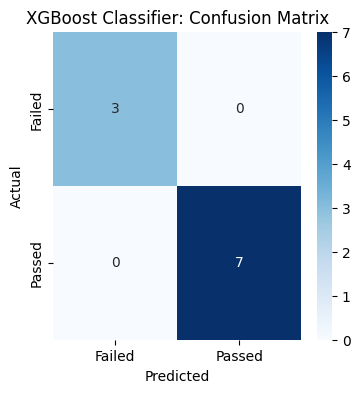

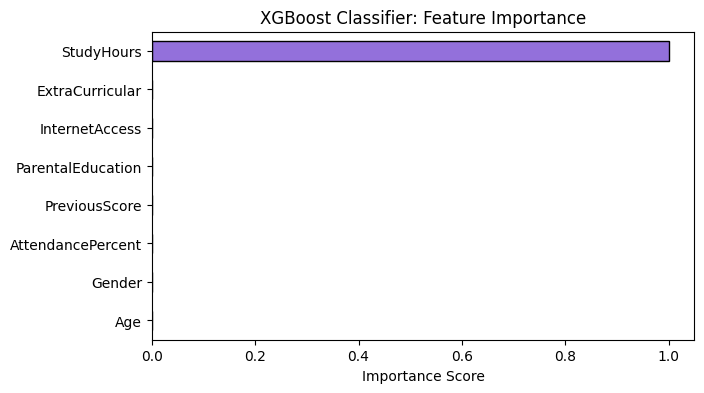

In [35]:
xgb_clf_cm = confusion_matrix(y_passed_test, xgb_clf_pred)

plt.figure(figsize=(4, 4))
sns.heatmap(xgb_clf_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Failed", "Passed"], yticklabels=["Failed", "Passed"])
plt.title("XGBoost Classifier: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

xgb_clf_importance = pd.Series(xgb_clf_model.feature_importances_, index=feature_columns)
xgb_clf_importance = xgb_clf_importance.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
xgb_clf_importance.plot(kind="barh", color="mediumpurple", edgecolor="black")
plt.title("XGBoost Classifier: Feature Importance")
plt.xlabel("Importance Score")
plt.show()

### Compare all six Classification models

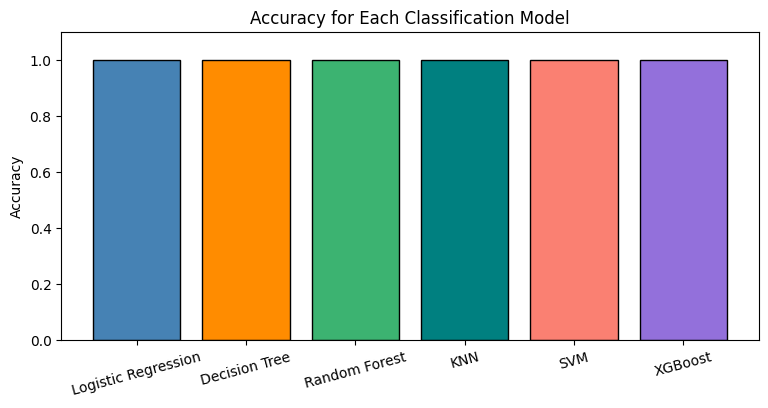

Accuracy Scores:
Logistic Regression: 1.0
Decision Tree: 1.0
Random Forest: 1.0
KNN: 1.0
SVM: 1.0
XGBoost: 1.0


In [36]:
clf_model_names = ["Logistic Regression", "Decision Tree", "Random Forest", "KNN", "SVM", "XGBoost"]
clf_accuracies = [log_acc, tree_clf_acc, forest_clf_acc, knn_acc, svm_acc, xgb_clf_acc]
clf_colors = ["steelblue", "darkorange", "mediumseagreen", "teal", "salmon", "mediumpurple"]

plt.figure(figsize=(9, 4))
plt.bar(clf_model_names, clf_accuracies, color=clf_colors, edgecolor="black")
plt.title("Accuracy for Each Classification Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.show()

print("Accuracy Scores:")
print("Logistic Regression:", round(log_acc, 3))
print("Decision Tree:", round(tree_clf_acc, 3))
print("Random Forest:", round(forest_clf_acc, 3))
print("KNN:", round(knn_acc, 3))
print("SVM:", round(svm_acc, 3))
print("XGBoost:", round(xgb_clf_acc, 3))

In [37]:
print("Full Comparison Table for Classification")

clf_full_table = pd.DataFrame({
    "Accuracy": [log_acc, tree_clf_acc, forest_clf_acc, knn_acc, svm_acc, xgb_clf_acc],
    "Precision": [log_precision, tree_clf_precision, forest_clf_precision, knn_precision, svm_precision, xgb_clf_precision],
    "Recall": [log_recall, tree_clf_recall, forest_clf_recall, knn_recall, svm_recall, xgb_clf_recall],
    "F1 Score": [log_f1, tree_clf_f1, forest_clf_f1, knn_f1, svm_f1, xgb_clf_f1],
}, index=clf_model_names)

clf_full_table.round(3)

Full Comparison Table for Classification


,Accuracy,Precision,Recall,F1 Score
Logistic Regression,1.0,1.0,1.0,1.0
Decision Tree,1.0,1.0,1.0,1.0
Random Forest,1.0,1.0,1.0,1.0
KNN,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0
XGBoost,1.0,1.0,1.0,1.0


## What we learned

We practiced every model from the whiteboard list, in plain code with
no custom functions.

Regression, predicting a number, FinalScore:
1. Linear Regression
2. Polynomial Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. XGBoost Regressor

For each one we checked R2, MAE, MSE, and RMSE. For the tree based
models we also looked at feature importance, which shows which input
columns the model relied on the most.

Classification, predicting a category, Passed:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. KNN
5. Support Vector Machine
6. XGBoost Classifier

For each one we checked Accuracy, Precision, Recall, and F1 Score, and
for most of them we also looked at a confusion matrix and feature
importance.

KNN and SVM do not have a feature_importances_ value, because they do
not build rules the way trees do, they compare distances or boundaries
instead. That is why those two are missing from the feature importance
charts.

You can reuse this same notebook on a new dataset. Just change the
file name in Step 2, change the column names in Step 7, and run the
notebook again from top to bottom.
